<a href="https://colab.research.google.com/github/naubergois/curso-yolo-colab/blob/main/notebooks/04-treino-com-dataset-proprio.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 4. Treinar o YOLO com um dataset

O modelo pronto conhece 80 classes. Para reconhecer algo novo (uma peça da sua fábrica, um tipo de placa, uma praga na folha), você treina com fotos rotuladas. O Ultralytics faz isso com uma chamada só.

Para caber numa aula, o treino usa o `coco8`: oito fotos (quatro de treino, quatro de validação), já no formato certo, que baixam sozinhas. Serve para entender o processo, não para ter um modelo bom. Isso pede centenas de imagens por classe.

> Aqui a GPU faz diferença: **Ambiente de execução → Alterar o tipo de ambiente → T4 GPU**.

In [1]:
!pip install -q ultralytics

## Como é um dataset YOLO

Um arquivo `.yaml` aponta as pastas de treino e validação e lista as classes. Para cada imagem existe um `.txt` com uma linha por objeto: `classe x_centro y_centro largura altura`, tudo de 0 a 1.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO
from ultralytics.utils import DATASETS_DIR

model = YOLO("yolov8n.pt")

## Treinar

Começamos dos pesos já treinados (`yolov8n.pt`). Isso se chama *transfer learning*: o modelo já sabe ver bordas e formas, só ajusta o final. Cinco épocas com imagens de 320 px levam poucos minutos.

In [3]:
treino = model.train(
    data="coco8.yaml",
    epochs=5,
    imgsz=320,
    batch=8,
    project="runs",
    name="coco8",
    exist_ok=True,
    plots=False,
    verbose=False,
)
pasta = Path(treino.save_dir)
print("Resultados em", pasta)

Ultralytics 8.4.180 🚀 Python-3.12.13 torch-2.14.1 CPU (Apple M4)



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             


...

Model summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 20.4it/s 0.0s

                   all          4         17      0.638      0.633      0.621      0.461


Speed: 0.2ms preprocess, 10.7ms inference, 0.0ms loss, 0.3ms postprocess per image


Resultados em runs/detect/runs/coco8


## O que o arquivo de rótulos tem

In [4]:
rotulo = sorted((DATASETS_DIR / "coco8" / "labels" / "train").glob("*.txt"))[0]
print(rotulo.name)
print(rotulo.read_text())

000000000009.txt
45 0.479492 0.688771 0.955609 0.5955
45 0.736516 0.247188 0.498875 0.476417
50 0.637063 0.732938 0.494125 0.510583
45 0.339438 0.418896 0.678875 0.7815
49 0.646836 0.132552 0.118047 0.0969375
49 0.773148 0.129802 0.0907344 0.0972292
49 0.668297 0.226906 0.131281 0.146896
49 0.642859 0.0792187 0.148063 0.148062



## Acompanhar as perdas

O `results.csv` guarda as métricas de cada época. Num dataset de verdade a perda (`loss`) cai época após época e o `mAP50`, que mede acerto na validação, sobe. Aqui são quatro fotos de treino e cinco épocas, então as curvas oscilam. O que importa é ver onde cada número mora.

 epoch  train/box_loss  train/cls_loss  metrics/mAP50(B)
     1         1.22887         2.08624           0.62097
     2         1.23576         2.45388           0.62097
     3         1.26120         3.28481           0.62097
     4         1.21124         2.74359           0.62097
     5         1.25983         2.01996           0.62097


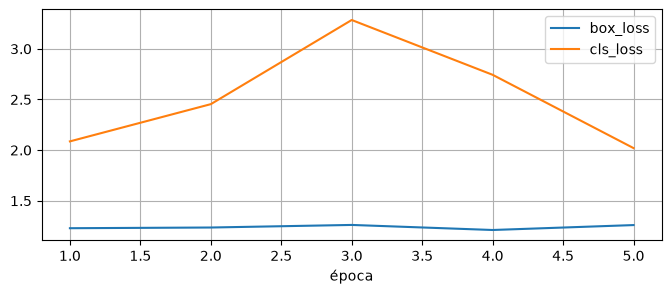

In [5]:
df = pd.read_csv(pasta / "results.csv")
df.columns = df.columns.str.strip()
print(df[["epoch", "train/box_loss", "train/cls_loss", "metrics/mAP50(B)"]].to_string(index=False))

plt.figure(figsize=(8, 3))
plt.plot(df["epoch"], df["train/box_loss"], label="box_loss")
plt.plot(df["epoch"], df["train/cls_loss"], label="cls_loss")
plt.xlabel("época")
plt.legend()
plt.grid(True)
plt.show()

## Usar o modelo treinado

O melhor peso fica em `weights/best.pt`. Ele carrega igual ao modelo original.

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg


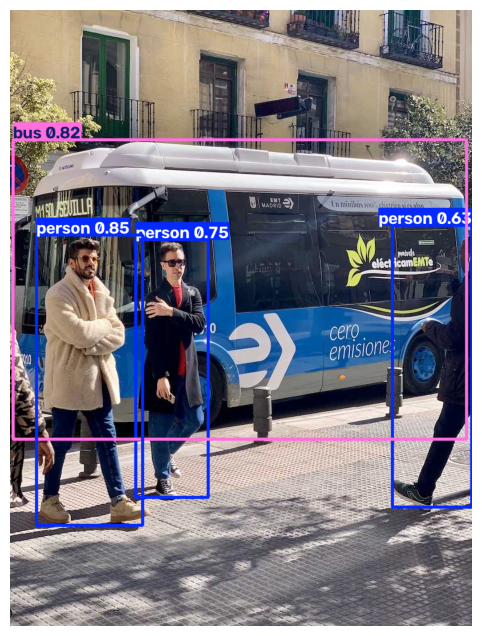

4 objetos detectados


In [6]:
melhor = YOLO(pasta / "weights" / "best.pt")
r = melhor("https://ultralytics.com/images/bus.jpg", verbose=False)[0]
plt.figure(figsize=(6, 8))
plt.imshow(r.plot()[:, :, ::-1])
plt.axis("off")
plt.show()
print(len(r.boxes), "objetos detectados")

## Exercícios

Seis exercícios para fixar a aula. Escreva a resposta na variável `resposta` e rode a célula: a função `conferir` diz na hora se está certo. Se travar, abra **Ver solução**.

Rode antes a célula de preparação abaixo. Ela só carrega as verificações.

In [7]:
# @title Preparação dos exercícios (rode, não precisa ler)
from collections import Counter
from functools import lru_cache

import cv2

_raiz = DATASETS_DIR / "coco8"
_linhas = [
    l.split()
    for f in sorted((_raiz / "labels" / "train").glob("*.txt"))
    for l in f.read_text().splitlines()
    if l.strip()
]
_por_classe = Counter(int(l[0]) for l in _linhas)


def _caixa_em_pixels():
    img = cv2.imread(str(_raiz / "images" / "train" / "000000000009.jpg"))
    h, w = img.shape[:2]
    linha = (_raiz / "labels" / "train" / "000000000009.txt").read_text().splitlines()[0]
    _, x, y, bw, bh = map(float, linha.split())
    return ((x - bw / 2) * w, (y - bh / 2) * h, (x + bw / 2) * w, (y + bh / 2) * h)


@lru_cache(None)
def _map50():
    return float(melhor.val(data="coco8.yaml", imgsz=320, verbose=False, plots=False).box.map50)


VERIFICAR = {
    1: lambda r: int(r) == len(list((_raiz / "images" / "train").glob("*.jpg"))),
    2: lambda r: int(r) == len(_linhas),
    3: lambda r: r in {model.names[c] for c, n in _por_classe.items() if n == max(_por_classe.values())},
    4: lambda r: all(abs(a - b) <= 2 for a, b in zip(r, _caixa_em_pixels())),
    5: lambda r: int(r) == int(df.loc[df["train/box_loss"].idxmin(), "epoch"]),
    6: lambda r: abs(float(r) - _map50()) < 1e-3,
}

_acertos = {}


def conferir(n, resposta):
    if resposta is None:
        print(f"Exercício {n}: ainda sem resposta.")
        return
    try:
        certo = bool(VERIFICAR[n](resposta))
    except Exception as erro:
        certo = False
        print(f"  (a verificação deu erro: {erro})")
    _acertos[n] = certo
    print(f"Exercício {n}: " + ("✅ certo!" if certo else "❌ ainda não. Releia o enunciado e tente de novo."))


def placar():
    print(f"{sum(_acertos.values())} de {len(VERIFICAR)} exercícios certos.")

### Exercício 1. Tamanho do treino

Quantas imagens há na pasta de treino do `coco8`?

<details>
<summary>Ver solução</summary>

```python
resposta = len(list((DATASETS_DIR / "coco8" / "images" / "train").glob("*.jpg")))
```

</details>

In [8]:
# Dica: As imagens ficam em DATASETS_DIR / "coco8" / "images" / "train".
resposta = None

conferir(1, resposta)

Exercício 1: ainda sem resposta.


### Exercício 2. Objetos rotulados

Quantos objetos rotulados existem, somando todos os arquivos `.txt` do treino? Cada linha é um objeto.

<details>
<summary>Ver solução</summary>

```python
rotulos = (DATASETS_DIR / "coco8" / "labels" / "train").glob("*.txt")
resposta = sum(len(f.read_text().strip().splitlines()) for f in rotulos)
```

</details>

In [9]:
# Dica: Some o número de linhas de cada arquivo em labels/train.
resposta = None

conferir(2, resposta)

Exercício 2: ainda sem resposta.


### Exercício 3. Classe mais rotulada

Qual classe mais aparece nos rótulos de treino? Responda com o nome, não com o número.

<details>
<summary>Ver solução</summary>

```python
cont = Counter()
for f in (DATASETS_DIR / "coco8" / "labels" / "train").glob("*.txt"):
    cont.update(int(l.split()[0]) for l in f.read_text().strip().splitlines())
resposta = model.names[cont.most_common(1)[0][0]]
```

</details>

In [10]:
# Dica: O primeiro número de cada linha é a classe; model.names traduz para nome.
resposta = None

conferir(3, resposta)

Exercício 3: ainda sem resposta.


### Exercício 4. De volta para pixels

Pegue a primeira linha do rótulo `000000000009.txt` e converta para pixels no formato `(x1, y1, x2, y2)`, usando o tamanho real da imagem `000000000009.jpg`.

<details>
<summary>Ver solução</summary>

```python
raiz = DATASETS_DIR / "coco8"
img = cv2.imread(str(raiz / "images" / "train" / "000000000009.jpg"))
h, w = img.shape[:2]
linha = (raiz / "labels" / "train" / "000000000009.txt").read_text().splitlines()[0]
_, x, y, bw, bh = map(float, linha.split())
resposta = (int((x - bw / 2) * w), int((y - bh / 2) * h), int((x + bw / 2) * w), int((y + bh / 2) * h))
```

</details>

In [11]:
# Dica: x1 = (x_centro - largura / 2) * largura_da_imagem, e assim por diante.
resposta = None

conferir(4, resposta)

Exercício 4: ainda sem resposta.


### Exercício 5. A melhor época

Em qual época a `train/box_loss` foi a menor?

<details>
<summary>Ver solução</summary>

```python
resposta = int(df.loc[df["train/box_loss"].idxmin(), "epoch"])
```

</details>

In [12]:
# Dica: df["coluna"].idxmin() dá a linha do menor valor.
resposta = None

conferir(5, resposta)

Exercício 5: ainda sem resposta.


### Exercício 6. Validar o modelo

Rode a validação do modelo treinado com `melhor.val(data="coco8.yaml", imgsz=320)` e responda com o `mAP50`.

<details>
<summary>Ver solução</summary>

```python
metricas = melhor.val(data="coco8.yaml", imgsz=320, verbose=False, plots=False)
resposta = metricas.box.map50
```

</details>

In [13]:
# Dica: O retorno de val() tem .box.map50.
resposta = None

conferir(6, resposta)

Exercício 6: ainda sem resposta.


In [14]:
placar()

0 de 6 exercícios certos.


## Para treinar com as suas fotos

1. Rotule as imagens no [Roboflow](https://roboflow.com) ou no [CVAT](https://www.cvat.ai) e exporte em **YOLOv8**.
2. Suba o `.zip` no Colab e descompacte.
3. Troque `data="coco8.yaml"` pelo `data.yaml` do seu dataset e aumente `epochs` para 50 ou mais.

O processo é o mesmo desta aula. Muda o tamanho do dataset e o tempo de treino.